<a href="https://colab.research.google.com/github/ShauryaPrakashVerma/Deep_Learning_PyTorch/blob/main/2_PyTorch_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch Workflow

PyTorch end to end workflow.

In [ ]:
what_we_are_covering = '''
1. Data (prepare and load)
2. Build model
3. Fitting the model to data (training)
4. making predictions and evaluating models
5. Saving and loading a model
6. Putting it all together
'''

print(what_we_are_covering)


1. Data (prepare and load)
2. Build model
3. Fitting the model to data (training)
4. making predictions and evaluating models
5. Saving and loading a model
6. Putting it all together



In [ ]:
import torch
from torch import nn       # nn contains are basic building blocks for neural networks (graphs)
import matplotlib.pyplot as plt


# Check PyTorch version
torch.__version__

'2.11.0+cpu'

## Data (Preparing and loading)

Data can be anything... in machine learning

* Excel Spreadsheet
* Images
* Videos
* Audio
* DNA
* Text


Machine Learning mainly has two parts:
1. Get data into a numerical representation.
2. Build a model to learn patterns in the numerical representation.

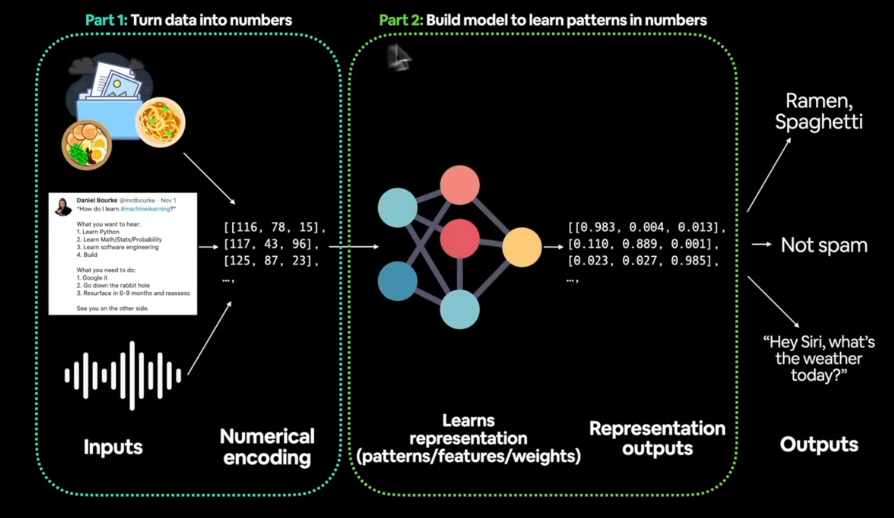

In [ ]:
# Create known parameters

weight = 0.7
bias = 0.3


# Create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

X[:10], y[:10], len(X), len(y)

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]),
 50,
 50)

## Splitting dataset into train and test

In [ ]:
# create a train /test split
train_split = int(0.8 * len(X))
train_split

40

In [ ]:
x_train, y_train = X[:train_split], y[:train_split]
x_test, y_test = X[:train_split], y[train_split:]

len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 40, 10)

In [ ]:
def plot_predictions(train_data=x_train,
                     train_labels = y_train,
                     test_data = x_test,
                     test_labels = y_test,
                     predictions= None):
  '''
  Plots training data, test data and compare predictions.
  '''
  print(train_data.shape, train_labels.shape)
  plt.figure(figsize=(10,7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="T", marker="s")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data", marker="o")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions", marker="*")


  plt.legend(prop={"size":14});
  plt.show()


torch.Size([40, 1]) torch.Size([40, 1])


ValueError: x and y must be the same size

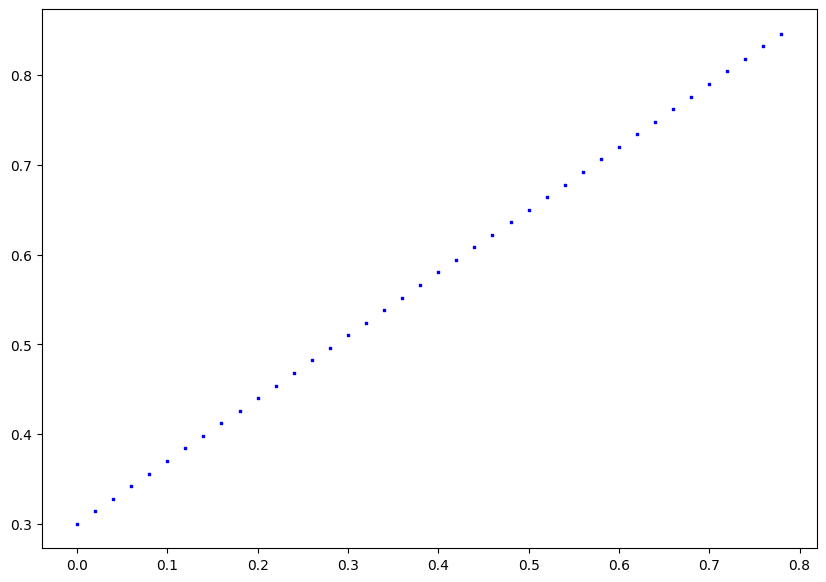

In [ ]:
plot_predictions()

# Build model

prerequisites: OOPS Python

---

This model does the following by:
1. Start with random values (weights and bias)
2. Look at training data and adjuat the random values to better represent (or get closer to) the ideal values (the weight and bias values we used to create the data)

---

How does it do so?
Two main algorithms:
1. Gradient Descent
2. Backpropagation

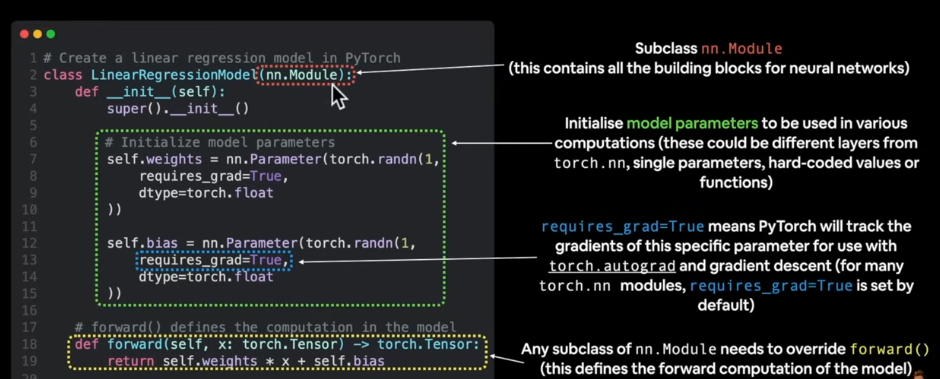

In [16]:
from torch import nn

In [17]:
# Linear regression model class

class LinearRegressionModel(nn.Module):     # nn.Module is the base class for all neural networks
  def __init__(self):
    super().__init__()


    # we wont be necessarily creating these in the future, we will be instead creating layers,
    # layers that the model needs
    self.weights = nn.Parameter(torch.randn(1,
                                            requires_grad = True,
                                            dtype = torch.float))
    self.bias = nn.Parameter(torch.randn(1,
                                         requires_grad=True,
                                         dtype=torch.float))


    # Forward method to define the computation in the model
    def forward(self, x:torch.Tensor) -> torch.Tensor:
      return self.weights * x + self.bias



### PyTorch model building essential

* torch.nn - contains all of the building blocks for computational graphs ( neural network)

* torch.nn.Parameter - what parameters should our model try and learn, often a PyTorch layer from torch.nn will set these fro us

* torch.nn.Module - base class for all neural network module. if you use it (subclass it) forward fucntion should be overwritten

* torch.optim - this is where the optimizers in PyTorch live, they will help with the gradient descent

* def forward() - All nn.Module subclasses require you to overwrite forward(), this method defines what happens in the computation

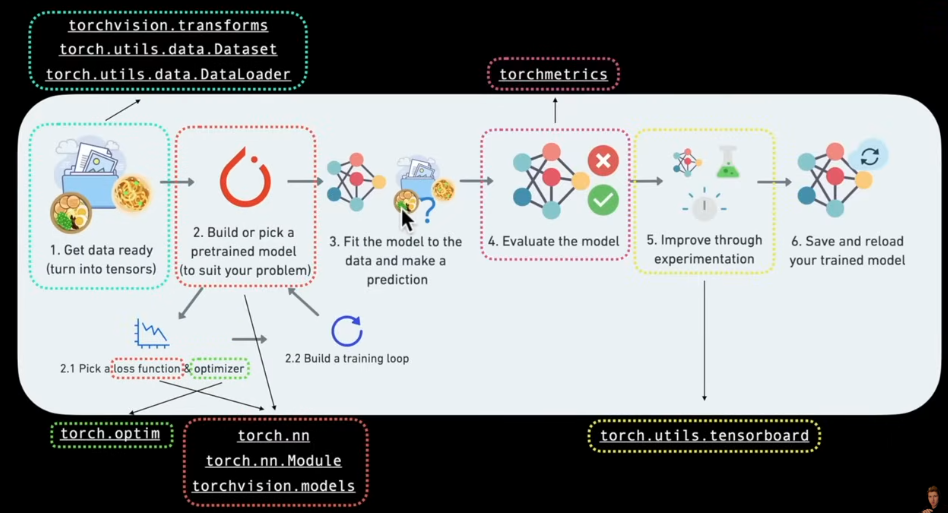

### Checking contents of our pyTorch model
We can check the parameters or what inside out model using .parameters()

In [33]:
# Creating a random seed
torch.manual_seed(42)

# Create an instance of the model (subclass of the nn.Module)
model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
5.25